In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Load the original dataset
data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name=0)

# Remove duplicate rows
clean_data = data.drop_duplicates().copy()

# Define input features and output target
X = clean_data[["AT", "V", "AP", "RH"]]
y = clean_data["PE"]

# Split data into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split temporary data into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Check dataset sizes
print("Cleaned dataset:", clean_data.shape)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Cleaned dataset: (9527, 5)
Training samples: 6668
Validation samples: 1429
Test samples: 1430


In [2]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create the decision tree model
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)

# Train the model
tree_model.fit(X_train, y_train)

# Predict training and validation data
tree_train_pred = tree_model.predict(X_train)
tree_val_pred = tree_model.predict(X_val)

# Evaluate training performance
tree_train_mae = mean_absolute_error(y_train, tree_train_pred)

# Evaluate validation performance
tree_mae = mean_absolute_error(y_val, tree_val_pred)
tree_rmse = np.sqrt(mean_squared_error(y_val, tree_val_pred))
tree_r2 = r2_score(y_val, tree_val_pred)

print("Decision Tree Regression Results:")
print(f"Training MAE: {tree_train_mae:.3f} MW")
print(f"Validation MAE: {tree_mae:.3f} MW")
print(f"Validation RMSE: {tree_rmse:.3f} MW")
print(f"Validation R2: {tree_r2:.3f}")

Decision Tree Regression Results:
Training MAE: 3.337 MW
Validation MAE: 3.504 MW
Validation RMSE: 4.670 MW
Validation R2: 0.927


In [3]:
depths = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15]

depth_results = []

for depth in depths:

    # Create and train decision tree
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Predict training and validation data
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Calculate errors
    train_mae = mean_absolute_error(y_train, train_pred)
    val_mae = mean_absolute_error(y_val, val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    # Store results
    depth_results.append({
        "Max Depth": depth,
        "Training MAE": train_mae,
        "Validation MAE": val_mae,
        "Validation RMSE": val_rmse
    })

# Display comparison table
depth_results_df = pd.DataFrame(depth_results)

print("Decision Tree Depth Comparison:")
display(depth_results_df.round(3))

Decision Tree Depth Comparison:


,Max Depth,Training MAE,Validation MAE,Validation RMSE
0,2,5.015,5.030,6.425
1,3,3.996,4.139,5.396
2,4,3.596,3.695,4.916
3,5,3.337,3.504,4.670
4,6,3.059,3.232,4.385
5,7,2.831,3.155,4.328
6,8,2.568,3.070,4.244
7,10,2.019,3.021,4.364
8,12,1.379,3.082,4.485
9,15,0.594,3.159,4.652


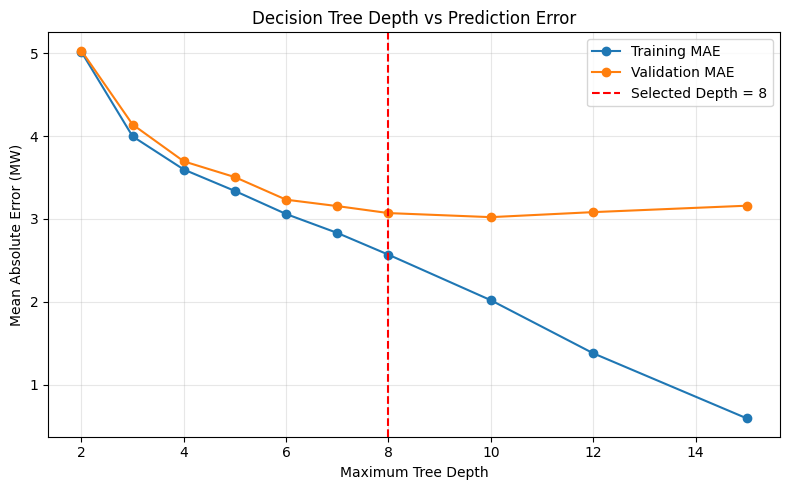

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Training MAE"],
    marker="o",
    label="Training MAE"
)

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

# Mark the selected tree depth
plt.axvline(x=8, color="red", linestyle="--",
            label="Selected Depth = 8")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean Absolute Error (MW)")
plt.title("Decision Tree Depth vs Prediction Error")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Create the selected model with maximum depth of 8
selected_tree = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)

# Train the selected model
selected_tree.fit(X_train, y_train)

# Make predictions
selected_train_pred = selected_tree.predict(X_train)
selected_val_pred = selected_tree.predict(X_val)

# Calculate training error
selected_train_mae = mean_absolute_error(
    y_train, selected_train_pred
)

# Calculate validation errors
selected_val_mae = mean_absolute_error(
    y_val, selected_val_pred
)

selected_val_rmse = np.sqrt(
    mean_squared_error(y_val, selected_val_pred)
)

selected_val_r2 = r2_score(
    y_val, selected_val_pred
)

# Display results
print("Selected Decision Tree (Depth = 8):")
print(f"Training MAE: {selected_train_mae:.3f} MW")
print(f"Validation MAE: {selected_val_mae:.3f} MW")
print(f"Validation RMSE: {selected_val_rmse:.3f} MW")
print(f"Validation R2: {selected_val_r2:.3f}")

Selected Decision Tree (Depth = 8):
Training MAE: 2.568 MW
Validation MAE: 3.070 MW
Validation RMSE: 4.244 MW
Validation R2: 0.940


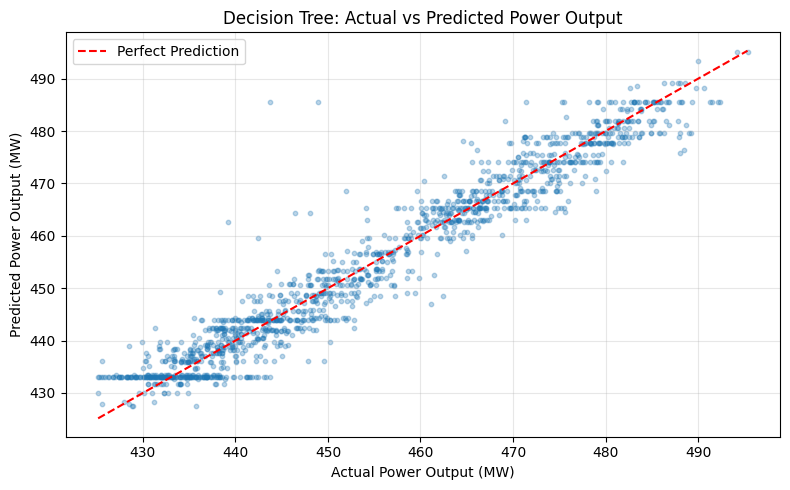

In [6]:
plt.figure(figsize=(8, 5))

# Plot actual and predicted values
plt.scatter(y_val, selected_val_pred, alpha=0.3, s=10)

# Draw the perfect prediction line
minimum = min(y_val.min(), selected_val_pred.min())
maximum = max(y_val.max(), selected_val_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Predicted Power Output (MW)")
plt.title("Decision Tree: Actual vs Predicted Power Output")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

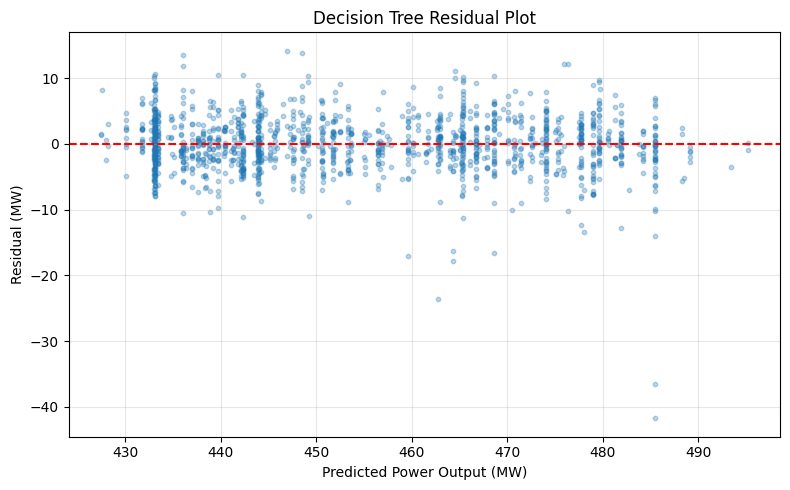

Mean Residual: 0.01 MW
Maximum Absolute Residual: 41.745 MW


In [7]:
# Calculate residuals
tree_residuals = y_val - selected_val_pred

# Plot residuals against predicted power output
plt.figure(figsize=(8, 5))

plt.scatter(
    selected_val_pred,
    tree_residuals,
    alpha=0.3,
    s=10
)

# Draw the zero residual line
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Power Output (MW)")
plt.ylabel("Residual (MW)")
plt.title("Decision Tree Residual Plot")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display residual statistics
print("Mean Residual:", round(tree_residuals.mean(), 3), "MW")
print("Maximum Absolute Residual:", round(np.abs(tree_residuals).max(), 3), "MW")

In [8]:
from sklearn.linear_model import LinearRegression

# Train linear regression using the same training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict training and validation data
linear_train_pred = linear_model.predict(X_train)
linear_val_pred = linear_model.predict(X_val)

# Calculate linear regression errors
linear_train_mae = mean_absolute_error(y_train, linear_train_pred)
linear_val_mae = mean_absolute_error(y_val, linear_val_pred)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree (Depth 8)"],
    "Training MAE": [linear_train_mae, selected_train_mae],
    "Validation MAE": [linear_val_mae, selected_val_mae]
})

# Calculate the difference between validation and training errors
comparison["MAE Gap"] = (
    comparison["Validation MAE"] - comparison["Training MAE"]
)

print("Training vs Validation Comparison:")
display(comparison.round(3))

Training vs Validation Comparison:


,Model,Training MAE,Validation MAE,MAE Gap
0,Linear Regression,3.603,3.587,-0.016
1,Decision Tree (Depth 8),2.568,3.070,0.502


In [9]:
# Calculate validation metrics for Linear Regression
linear_val_rmse = np.sqrt(
    mean_squared_error(y_val, linear_val_pred)
)
linear_val_r2 = r2_score(y_val, linear_val_pred)

# Create a summary table
validation_summary = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree (Depth 8)"],
    "Training MAE": [linear_train_mae, selected_train_mae],
    "Validation MAE": [linear_val_mae, selected_val_mae],
    "Validation RMSE": [linear_val_rmse, selected_val_rmse],
    "Validation R2": [linear_val_r2, selected_val_r2]
})

print("Model Validation Summary:")
display(validation_summary.round(3))

# Calculate improvement of Decision Tree over Linear Regression
mae_reduction = (
    (linear_val_mae - selected_val_mae) / linear_val_mae * 100
)

rmse_reduction = (
    (linear_val_rmse - selected_val_rmse) / linear_val_rmse * 100
)

print(f"\nValidation MAE reduction: {mae_reduction:.2f}%")
print(f"Validation RMSE reduction: {rmse_reduction:.2f}%")

Model Validation Summary:


,Model,Training MAE,Validation MAE,Validation RMSE,Validation R2
0,Linear Regression,3.603,3.587,4.630,0.928
1,Decision Tree (Depth 8),2.568,3.070,4.244,0.940



Validation MAE reduction: 14.41%
Validation RMSE reduction: 8.33%
